<a href="https://colab.research.google.com/github/2403A51L1/Assign3/blob/master/Quantum_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q numpy pandas matplotlib seaborn scikit-learn psutil

In [2]:
import os
import time
import zipfile
import tracemalloc
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import SelectFromModel

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
uploaded = files.upload()

zip_files = [f for f in uploaded.keys() if f.lower().endswith(".zip")]

if zip_files:
    zip_path = zip_files[0]

    extract_path = "/content/wine_dataset"

    with zipfile.ZipFile(zip_path, 'r') as z:
        z.extractall(extract_path)

    print("ZIP extracted successfully!")
    print("Extracted files:")

    for root, dirs, filenames in os.walk(extract_path):
        for filename in filenames:
            print(os.path.join(root, filename))
else:
    print("No ZIP uploaded. We can use the built-in Wine dataset.")

Saving wine.zip to wine (2).zip
ZIP extracted successfully!
Extracted files:
/content/wine_dataset/wine.names
/content/wine_dataset/Index
/content/wine_dataset/wine.data


In [5]:
wine_file = None

if zip_files:
    for root, dirs, filenames in os.walk("/content/wine_dataset"):
        for filename in filenames:
            if filename.lower() == "wine.data":
                wine_file = os.path.join(root, filename)
                break
        if wine_file:
            break

if wine_file:
    df = pd.read_csv(wine_file, header=None)

    y = df.iloc[:, 0].astype(int).values
    X = df.iloc[:, 1:].copy()

    X.columns = [
        "Alcohol", "Malic acid", "Ash",
        "Alcalinity of ash", "Magnesium",
        "Total phenols", "Flavanoids",
        "Nonflavanoid phenols", "Proanthocyanins",
        "Color intensity", "Hue",
        "OD280/OD315", "Proline"
    ]

    print("Loaded original UCI wine.data file")

else:
    wine = load_wine(as_frame=True)

    X = wine.data.copy()
    y = wine.target.values

    print("Loaded Wine dataset using scikit-learn")

feature_names = list(X.columns)

print("\nDataset shape:", X.shape)
print("Number of features:", len(feature_names))
print("Number of classes:", len(np.unique(y)))
print("\nClass distribution:")
print(pd.Series(y).value_counts().sort_index())

print("\nFirst five rows:")
display(X.head())

Loaded original UCI wine.data file

Dataset shape: (178, 13)
Number of features: 13
Number of classes: 3

Class distribution:
1    59
2    71
3    48
Name: count, dtype: int64

First five rows:


,Alcohol,Malic acid,Ash,Alcalinity of ash,Magnesium,Total phenols,Flavanoids,Nonflavanoid phenols,Proanthocyanins,Color intensity,Hue,OD280/OD315,Proline
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


In [6]:
print("Missing values:")
print(X.isnull().sum())

print("\nDuplicate rows:", X.duplicated().sum())

# Remove duplicate records, if any
data = X.copy()
data["Target"] = y

data = data.drop_duplicates()

X = data.drop("Target", axis=1)
y = data["Target"].values

# First split: 80% development, 20% testing
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

# Second split: 60% training, 20% validation
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y_dev
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("\nTraining samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

print("\nPreprocessing completed!")

Missing values:
Alcohol                 0
Malic acid              0
Ash                     0
Alcalinity of ash       0
Magnesium               0
Total phenols           0
Flavanoids              0
Nonflavanoid phenols    0
Proanthocyanins         0
Color intensity         0
Hue                     0
OD280/OD315             0
Proline                 0
dtype: int64

Duplicate rows: 0

Training samples: 106
Validation samples: 36
Testing samples: 36

Preprocessing completed!


In [7]:
def create_model():
    return SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        decision_function_shape="ovr"
    )


fitness_evaluations = 0

def calculate_fitness(chromosome):

    global fitness_evaluations

    selected = np.where(chromosome == 1)[0]

    if len(selected) == 0:
        return 0.0

    fitness_evaluations += 1

    model = create_model()

    model.fit(
        X_train_scaled[:, selected],
        y_train
    )

    predictions = model.predict(
        X_val_scaled[:, selected]
    )

    validation_f1 = f1_score(
        y_val,
        predictions,
        average="macro",
        zero_division=0
    )

    # Small penalty to encourage fewer features
    penalty = 0.01 * (len(selected) / len(feature_names))

    fitness = validation_f1 - penalty

    return fitness


print("Fitness function ready!")

Fitness function ready!


In [8]:
class QuantumInspiredGA:

    def __init__(
        self,
        population_size=20,
        generations=30,
        rotation_angle=0.01,
        mutation_rate=0.05
    ):

        self.population_size = population_size
        self.generations = generations
        self.rotation_angle = rotation_angle
        self.mutation_rate = mutation_rate

        self.n_features = len(feature_names)

        # Probability encoding
        self.theta = np.full(
            self.n_features,
            np.pi / 4
        )

        self.best_solution = None
        self.best_fitness = -np.inf

        self.history = []
        self.evaluations = 0

    def measure(self):

        probabilities = np.sin(self.theta) ** 2

        population = (
            np.random.random(
                (self.population_size, self.n_features)
            ) < probabilities
        ).astype(int)

        # Ensure at least one feature is selected
        for individual in population:
            if np.sum(individual) == 0:
                individual[np.random.randint(self.n_features)] = 1

        return population

    def optimize(self):

        for generation in range(self.generations):

            population = self.measure()

            fitness_values = []

            for chromosome in population:

                fitness = calculate_fitness(chromosome)

                self.evaluations += 1
                fitness_values.append(fitness)

                if fitness > self.best_fitness:

                    self.best_fitness = fitness
                    self.best_solution = chromosome.copy()

            # Find the best individual in this generation
            generation_best = population[
                np.argmax(fitness_values)
            ]

            # Probability rotation update
            for i in range(self.n_features):

                if generation_best[i] == 1:
                    self.theta[i] += self.rotation_angle
                else:
                    self.theta[i] -= self.rotation_angle

            # Mutation of probability angles
            for i in range(self.n_features):

                if np.random.random() < self.mutation_rate:

                    self.theta[i] = np.pi / 2 - self.theta[i]

            # Keep angles within valid bounds
            self.theta = np.clip(
                self.theta,
                0.01,
                np.pi / 2 - 0.01
            )

            self.history.append(self.best_fitness)

            print(
                f"Generation {generation + 1}/{self.generations} "
                f"| Best Fitness: {self.best_fitness:.4f} "
                f"| Selected Features: {np.sum(self.best_solution)}"
            )

        return self.best_solution, self.best_fitness


qiga = QuantumInspiredGA(
    population_size=20,
    generations=30,
    rotation_angle=0.01,
    mutation_rate=0.05
)

qiga_start = time.time()

qiga_solution, qiga_fitness = qiga.optimize()

qiga_time = time.time() - qiga_start

print("\nQuantum-Inspired Optimization Completed!")

print("Best Fitness:", qiga_fitness)
print("Selected Features:", np.sum(qiga_solution))

print("\nSelected feature names:")

for i in np.where(qiga_solution == 1)[0]:
    print(feature_names[i])

Generation 1/30 | Best Fitness: 0.9938 | Selected Features: 8
Generation 2/30 | Best Fitness: 0.9938 | Selected Features: 8
Generation 3/30 | Best Fitness: 0.9954 | Selected Features: 6
Generation 4/30 | Best Fitness: 0.9962 | Selected Features: 5
Generation 5/30 | Best Fitness: 0.9962 | Selected Features: 5
Generation 6/30 | Best Fitness: 0.9962 | Selected Features: 5
Generation 7/30 | Best Fitness: 0.9962 | Selected Features: 5
Generation 8/30 | Best Fitness: 0.9962 | Selected Features: 5
Generation 9/30 | Best Fitness: 0.9962 | Selected Features: 5
Generation 10/30 | Best Fitness: 0.9962 | Selected Features: 5
Generation 11/30 | Best Fitness: 0.9962 | Selected Features: 5
Generation 12/30 | Best Fitness: 0.9962 | Selected Features: 5
Generation 13/30 | Best Fitness: 0.9962 | Selected Features: 5
Generation 14/30 | Best Fitness: 0.9962 | Selected Features: 5
Generation 15/30 | Best Fitness: 0.9962 | Selected Features: 5
Generation 16/30 | Best Fitness: 0.9962 | Selected Features: 5
G

In [9]:
def classical_ga(
    population_size=20,
    generations=30,
    crossover_rate=0.8,
    mutation_rate=0.05
):

    n = len(feature_names)

    population = np.random.randint(
        0, 2,
        (population_size, n)
    )

    history = []

    best_solution = None
    best_fitness = -np.inf

    evaluations = 0

    def evaluate(chromosome):

        nonlocal evaluations

        if np.sum(chromosome) == 0:
            return 0.0

        evaluations += 1
        return calculate_fitness(chromosome)

    for generation in range(generations):

        fitness = np.array([
            evaluate(individual)
            for individual in population
        ])

        idx = np.argmax(fitness)

        if fitness[idx] > best_fitness:
            best_fitness = fitness[idx]
            best_solution = population[idx].copy()

        new_population = []

        while len(new_population) < population_size:

            # Tournament selection
            candidates = np.random.choice(
                population_size, 3, replace=False
            )

            p1 = population[
                candidates[np.argmax(fitness[candidates])]
            ].copy()

            candidates = np.random.choice(
                population_size, 3, replace=False
            )

            p2 = population[
                candidates[np.argmax(fitness[candidates])]
            ].copy()

            # Crossover
            if np.random.random() < crossover_rate:

                point = np.random.randint(1, n)

                child = np.concatenate([
                    p1[:point],
                    p2[point:]
                ])

            else:
                child = p1.copy()

            # Mutation
            mask = np.random.random(n) < mutation_rate
            child[mask] = 1 - child[mask]

            if np.sum(child) == 0:
                child[np.random.randint(n)] = 1

            new_population.append(child)

        population = np.array(new_population)

        history.append(best_fitness)

        print(
            f"GA Generation {generation + 1}/{generations} "
            f"| Fitness: {best_fitness:.4f}"
        )

    return best_solution, best_fitness, history, evaluations


ga_start = time.time()

ga_solution, ga_fitness, ga_history, ga_evaluations = classical_ga()

ga_time = time.time() - ga_start

print("\nClassical GA completed!")
print("Best Fitness:", ga_fitness)
print("Selected Features:", np.sum(ga_solution))

GA Generation 1/30 | Fitness: 0.9938
GA Generation 2/30 | Fitness: 0.9962
GA Generation 3/30 | Fitness: 0.9969
GA Generation 4/30 | Fitness: 0.9969
GA Generation 5/30 | Fitness: 0.9969
GA Generation 6/30 | Fitness: 0.9969
GA Generation 7/30 | Fitness: 0.9969
GA Generation 8/30 | Fitness: 0.9969
GA Generation 9/30 | Fitness: 0.9969
GA Generation 10/30 | Fitness: 0.9969
GA Generation 11/30 | Fitness: 0.9977
GA Generation 12/30 | Fitness: 0.9977
GA Generation 13/30 | Fitness: 0.9977
GA Generation 14/30 | Fitness: 0.9977
GA Generation 15/30 | Fitness: 0.9977
GA Generation 16/30 | Fitness: 0.9977
GA Generation 17/30 | Fitness: 0.9977
GA Generation 18/30 | Fitness: 0.9977
GA Generation 19/30 | Fitness: 0.9977
GA Generation 20/30 | Fitness: 0.9977
GA Generation 21/30 | Fitness: 0.9977
GA Generation 22/30 | Fitness: 0.9977
GA Generation 23/30 | Fitness: 0.9977
GA Generation 24/30 | Fitness: 0.9977
GA Generation 25/30 | Fitness: 0.9977
GA Generation 26/30 | Fitness: 0.9977
GA Generation 27/30 |

In [10]:
def random_search(iterations=100):

    best_solution = None
    best_fitness = -np.inf

    history = []
    evaluations = 0

    n = len(feature_names)

    for i in range(iterations):

        chromosome = np.random.randint(0, 2, n)

        if np.sum(chromosome) == 0:
            chromosome[np.random.randint(n)] = 1

        fitness = calculate_fitness(chromosome)

        evaluations += 1

        if fitness > best_fitness:

            best_fitness = fitness
            best_solution = chromosome.copy()

        history.append(best_fitness)

    return best_solution, best_fitness, history, evaluations


rs_start = time.time()

rs_solution, rs_fitness, rs_history, rs_evaluations = random_search(100)

rs_time = time.time() - rs_start

print("Random Search completed!")
print("Best Fitness:", rs_fitness)
print("Selected Features:", np.sum(rs_solution))

Random Search completed!
Best Fitness: 0.9961538461538462
Selected Features: 5


In [11]:
def l1_feature_selection():

    best_result = None
    best_fitness = -np.inf

    best_C = None

    for C in [0.01, 0.1, 1, 10]:

        selector_model = LogisticRegression(
            penalty="l1",
            solver="saga",
            C=C,
            max_iter=10000,
            random_state=RANDOM_STATE
        )

        selector_model.fit(
            X_train_scaled,
            y_train
        )

        selector = SelectFromModel(
            selector_model,
            prefit=True,
            threshold=1e-5
        )

        mask = selector.get_support()

        if not np.any(mask):
            continue

        chromosome = mask.astype(int)

        fitness = calculate_fitness(chromosome)

        if fitness > best_fitness:

            best_fitness = fitness
            best_result = chromosome.copy()
            best_C = C

    if best_result is None:
        raise RuntimeError("L1 selection did not select any features.")

    return best_result, best_fitness, best_C


l1_start = time.time()

l1_solution, l1_fitness, l1_best_C = l1_feature_selection()

l1_time = time.time() - l1_start

print("L1 Selection completed!")
print("Best C:", l1_best_C)
print("Best Fitness:", l1_fitness)
print("Selected Features:", np.sum(l1_solution))

L1 Selection completed!
Best C: 0.1
Best Fitness: 0.9946153846153846
Selected Features: 7


In [12]:
solutions = {
    "Quantum-Inspired GA": qiga_solution,
    "Classical GA": ga_solution,
    "Random Search": rs_solution,
    "L1 Selection": l1_solution
}

fitness_results = {
    "Quantum-Inspired GA": qiga_fitness,
    "Classical GA": ga_fitness,
    "Random Search": rs_fitness,
    "L1 Selection": l1_fitness
}

times = {
    "Quantum-Inspired GA": qiga_time,
    "Classical GA": ga_time,
    "Random Search": rs_time,
    "L1 Selection": l1_time
}

evaluations = {
    "Quantum-Inspired GA": qiga.evaluations,
    "Classical GA": ga_evaluations,
    "Random Search": rs_evaluations,
    "L1 Selection": 4
}

comparison = []

for name, solution in solutions.items():

    selected = [
        feature_names[i]
        for i in np.where(solution == 1)[0]
    ]

    comparison.append({
        "Algorithm": name,
        "Validation Fitness": fitness_results[name],
        "Selected Feature Count": len(selected),
        "Selected Features": ", ".join(selected),
        "Execution Time (seconds)": times[name],
        "Fitness Evaluations": evaluations[name]
    })

comparison_df = pd.DataFrame(comparison)

display(comparison_df.round(4))

,Algorithm,Validation Fitness,Selected Feature Count,Selected Features,Execution Time (seconds),Fitness Evaluations
0,Quantum-Inspired GA,0.9969,4,"Alcohol, Malic acid, Flavanoids, Proline",3.8782,600
1,Classical GA,0.9977,3,"Alcohol, OD280/OD315, Proline",8.1483,600
2,Random Search,0.9962,5,"Flavanoids, Nonflavanoid phenols, Proanthocyan...",0.5751,100
3,L1 Selection,0.9946,7,"Alcohol, Malic acid, Flavanoids, Color intensi...",0.2326,4



Quantum-Inspired GA
Selected features: 4
Accuracy: 0.9444
Macro F1: 0.9407
Precision: 0.9583
Recall/Sensitivity: 0.9333
Specificity: 0.9697
ROC AUC: 0.9815

Classification Report:
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        12
           2       0.88      1.00      0.93        14
           3       1.00      0.80      0.89        10

    accuracy                           0.94        36
   macro avg       0.96      0.93      0.94        36
weighted avg       0.95      0.94      0.94        36



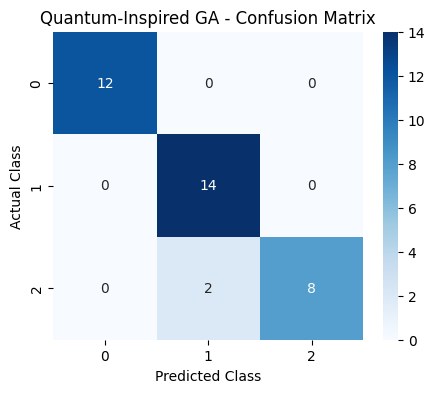


Classical GA
Selected features: 3
Accuracy: 0.9444
Macro F1: 0.9441
Precision: 0.9444
Recall/Sensitivity: 0.9524
Specificity: 0.9744
ROC AUC: 1.0

Classification Report:
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        12
           2       1.00      0.86      0.92        14
           3       0.83      1.00      0.91        10

    accuracy                           0.94        36
   macro avg       0.94      0.95      0.94        36
weighted avg       0.95      0.94      0.94        36



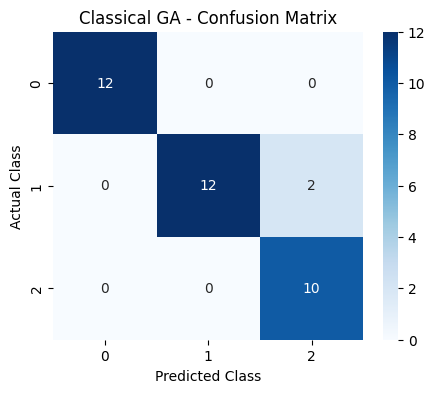


Random Search
Selected features: 5
Accuracy: 0.9444
Macro F1: 0.9452
Precision: 0.9441
Recall/Sensitivity: 0.9524
Specificity: 0.9733
ROC AUC: 1.0

Classification Report:
              precision    recall  f1-score   support

           1       0.92      1.00      0.96        12
           2       1.00      0.86      0.92        14
           3       0.91      1.00      0.95        10

    accuracy                           0.94        36
   macro avg       0.94      0.95      0.95        36
weighted avg       0.95      0.94      0.94        36



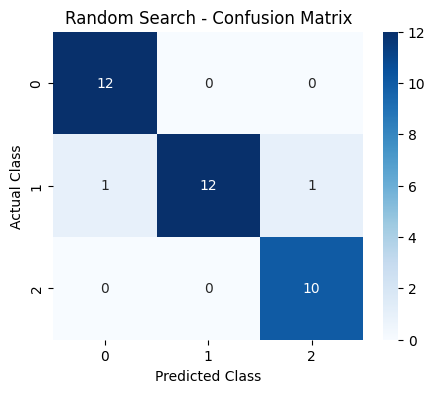


L1 Selection
Selected features: 7
Accuracy: 0.9722
Macro F1: 0.971
Precision: 0.9778
Recall/Sensitivity: 0.9667
Specificity: 0.9848
ROC AUC: 0.9989

Classification Report:
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        12
           2       0.93      1.00      0.97        14
           3       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36



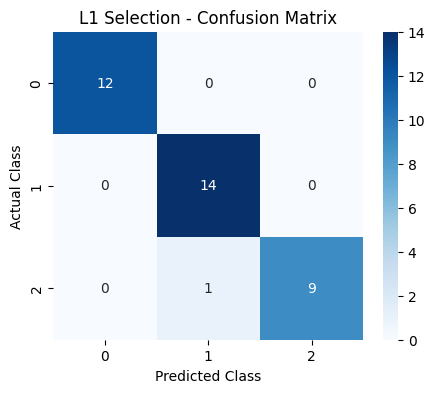


FINAL HELD-OUT TEST RESULTS


,Algorithm,Accuracy,Macro F1,Precision,Recall/Sensitivity,Specificity,ROC AUC,Feature Count
0,Quantum-Inspired GA,0.9444,0.9407,0.9583,0.9333,0.9697,0.9815,4
1,Classical GA,0.9444,0.9441,0.9444,0.9524,0.9744,1.0000,3
2,Random Search,0.9444,0.9452,0.9441,0.9524,0.9733,1.0000,5
3,L1 Selection,0.9722,0.9710,0.9778,0.9667,0.9848,0.9989,7


In [14]:
def create_model():
    # Redefine create_model with probability=True so we can retrieve proper probabilities for ROC AUC
    return SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        decision_function_shape="ovr",
        probability=True
    )

def calculate_specificity(y_true, y_pred):

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=np.unique(y)
    )

    specificities = []

    for i in range(len(cm)):

        TP = cm[i, i]

        FN = cm[i, :].sum() - TP

        FP = cm[:, i].sum() - TP

        TN = cm.sum() - TP - FN - FP

        specificity = TN / (TN + FP) if (TN + FP) > 0 else 0

        specificities.append(specificity)

    return np.mean(specificities)


def evaluate_algorithm(name, solution):

    selected = np.where(solution == 1)[0]

    Xtr = X_train_scaled[:, selected]
    Xte = X_test_scaled[:, selected]

    model = create_model()

    model.fit(Xtr, y_train)

    predictions = model.predict(Xte)

    # Retrieve actual probabilities instead of raw decision function scores
    probabilities = model.predict_proba(Xte)

    accuracy = accuracy_score(y_test, predictions)

    precision = precision_score(
        y_test, predictions,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_test, predictions,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_test, predictions,
        average="macro",
        zero_division=0
    )

    specificity = calculate_specificity(
        y_test, predictions
    )

    auc = roc_auc_score(
        y_test,
        probabilities,
        multi_class="ovr",
        average="macro"
    )

    print("\n", "=" * 55)
    print(name)
    print("=" * 55)

    print("Selected features:", len(selected))
    print("Accuracy:", round(accuracy, 4))
    print("Macro F1:", round(f1, 4))
    print("Precision:", round(precision, 4))
    print("Recall/Sensitivity:", round(recall, 4))
    print("Specificity:", round(specificity, 4))
    print("ROC AUC:", round(auc, 4))

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        predictions,
        zero_division=0
    ))

    cm = confusion_matrix(y_test, predictions)

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues"
    )

    plt.title(name + " - Confusion Matrix")
    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")
    plt.show()

    return {
        "Algorithm": name,
        "Accuracy": accuracy,
        "Macro F1": f1,
        "Precision": precision,
        "Recall/Sensitivity": recall,
        "Specificity": specificity,
        "ROC AUC": auc,
        "Feature Count": len(selected)
    }


final_results = []

for name, solution in solutions.items():

    result = evaluate_algorithm(name, solution)

    final_results.append(result)

final_df = pd.DataFrame(final_results)

print("\nFINAL HELD-OUT TEST RESULTS")

display(final_df.round(4))

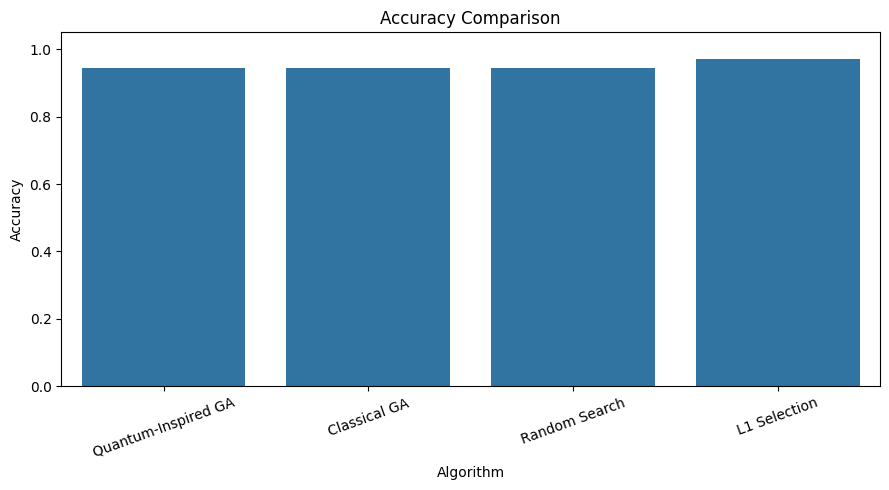

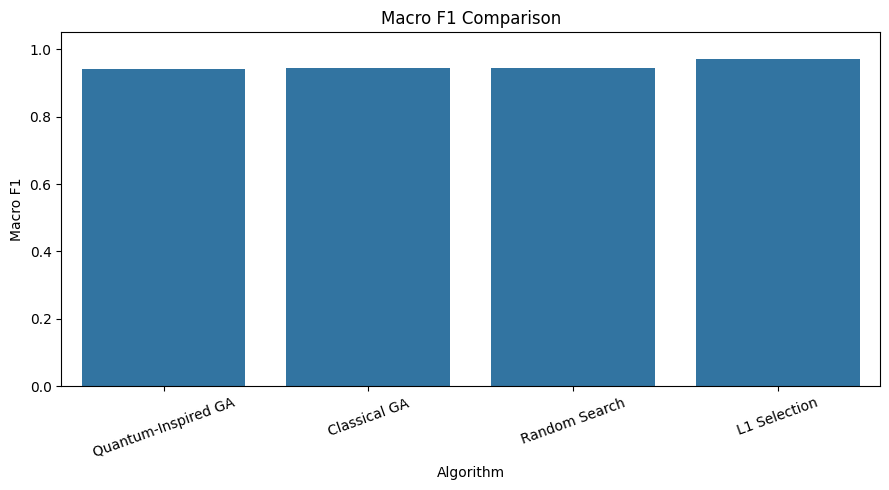

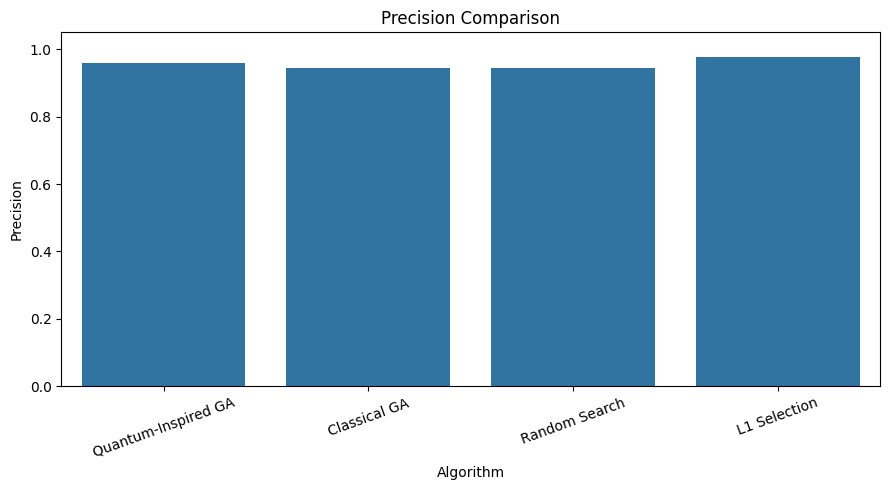

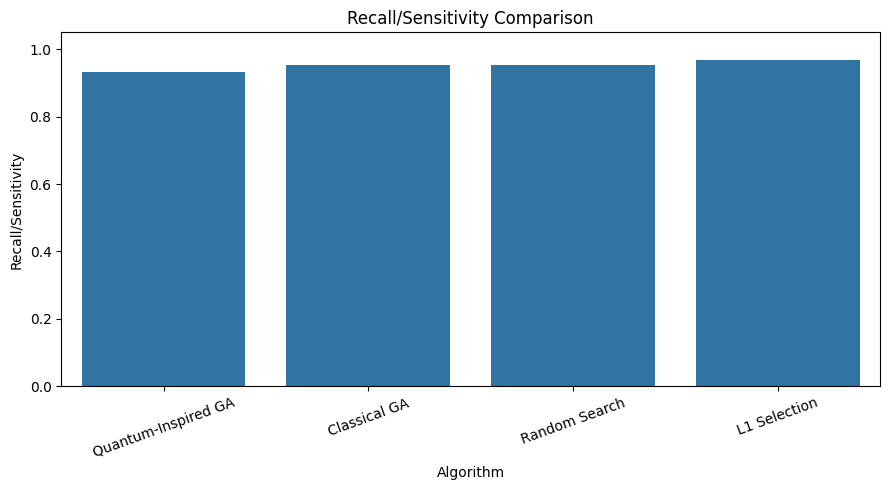

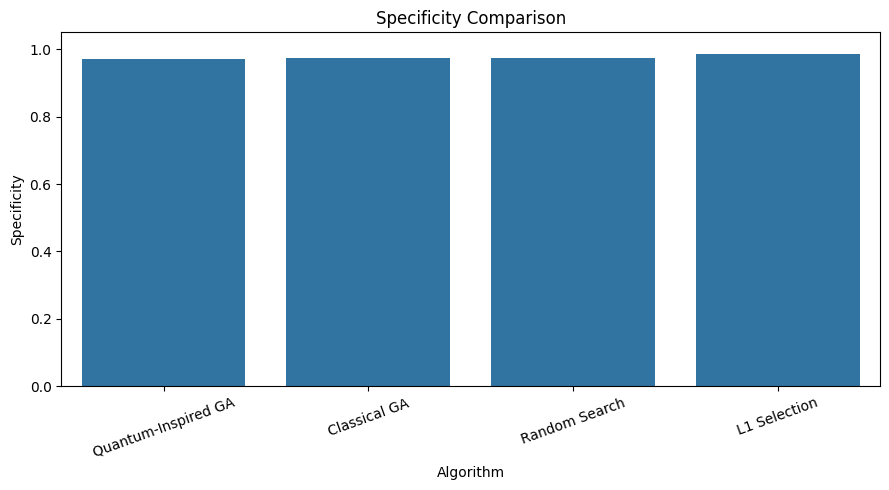

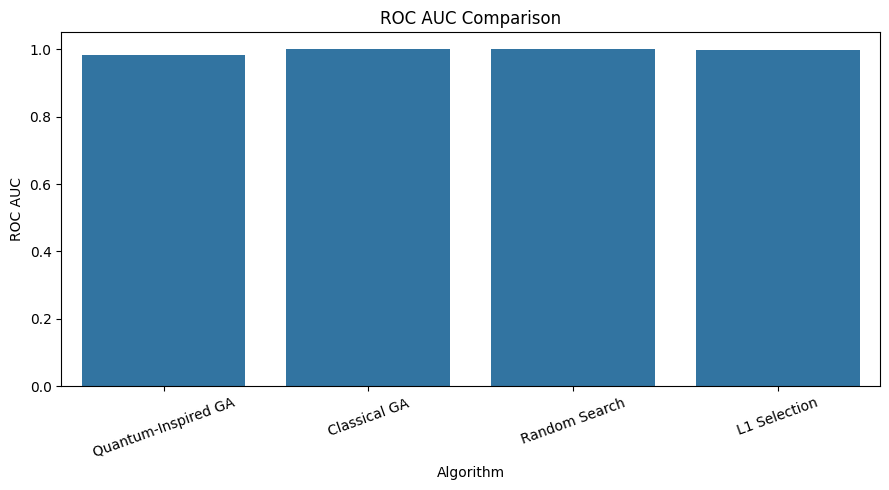

In [15]:
metrics = [
    "Accuracy",
    "Macro F1",
    "Precision",
    "Recall/Sensitivity",
    "Specificity",
    "ROC AUC"
]

for metric in metrics:

    plt.figure(figsize=(9, 5))

    sns.barplot(
        data=final_df,
        x="Algorithm",
        y=metric
    )

    plt.title(metric + " Comparison")

    plt.ylabel(metric)

    plt.xticks(rotation=20)

    plt.ylim(0, 1.05)

    plt.tight_layout()

    plt.show()

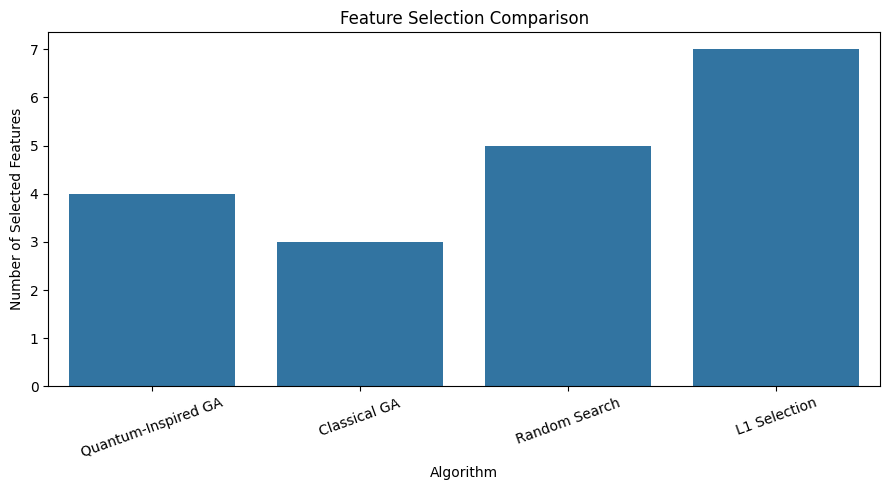

In [16]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=final_df,
    x="Algorithm",
    y="Feature Count"
)

plt.title("Feature Selection Comparison")

plt.ylabel("Number of Selected Features")

plt.xticks(rotation=20)

plt.tight_layout()

plt.show()

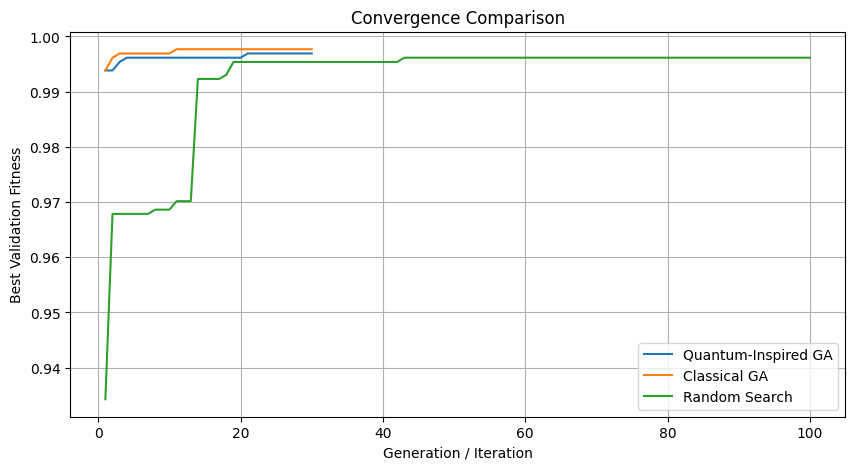

In [17]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(qiga.history) + 1),
    qiga.history,
    label="Quantum-Inspired GA"
)

plt.plot(
    range(1, len(ga_history) + 1),
    ga_history,
    label="Classical GA"
)

plt.plot(
    range(1, len(rs_history) + 1),
    rs_history,
    label="Random Search"
)

plt.xlabel("Generation / Iteration")

plt.ylabel("Best Validation Fitness")

plt.title("Convergence Comparison")

plt.legend()

plt.grid(True)

plt.show()

In [18]:
tracemalloc.start()

In [19]:
current_memory, peak_memory = tracemalloc.get_traced_memory()

print("Current Python memory:", round(current_memory / 1024, 2), "KB")

print("Peak Python memory:", round(peak_memory / 1024, 2), "KB")

print("\nExecution time comparison:")

for name, execution_time in times.items():

    print(name, ":", round(execution_time, 4), "seconds")

tracemalloc.stop()

Current Python memory: 34.0 KB
Peak Python memory: 70.75 KB

Execution time comparison:
Quantum-Inspired GA : 3.8782 seconds
Classical GA : 8.1483 seconds
Random Search : 0.5751 seconds
L1 Selection : 0.2326 seconds


In [20]:
rotation_angles = [0.005, 0.01, 0.02]

sensitivity_results = []

for angle in rotation_angles:

    print("\nTesting rotation angle:", angle)

    np.random.seed(42)

    algorithm = QuantumInspiredGA(
        population_size=20,
        generations=30,
        rotation_angle=angle,
        mutation_rate=0.05
    )

    solution, fitness = algorithm.optimize()

    sensitivity_results.append({
        "Rotation Angle": angle,
        "Validation Fitness": fitness,
        "Selected Features": np.sum(solution),
        "Fitness Evaluations": algorithm.evaluations
    })

sensitivity_df = pd.DataFrame(sensitivity_results)

print("\nPARAMETER SENSITIVITY RESULTS")

display(sensitivity_df.round(4))


Testing rotation angle: 0.005
Generation 1/30 | Best Fitness: 0.9938 | Selected Features: 8
Generation 2/30 | Best Fitness: 0.9938 | Selected Features: 8
Generation 3/30 | Best Fitness: 0.9954 | Selected Features: 6
Generation 4/30 | Best Fitness: 0.9962 | Selected Features: 5
Generation 5/30 | Best Fitness: 0.9962 | Selected Features: 5
Generation 6/30 | Best Fitness: 0.9962 | Selected Features: 5
Generation 7/30 | Best Fitness: 0.9962 | Selected Features: 5
Generation 8/30 | Best Fitness: 0.9962 | Selected Features: 5
Generation 9/30 | Best Fitness: 0.9962 | Selected Features: 5
Generation 10/30 | Best Fitness: 0.9962 | Selected Features: 5
Generation 11/30 | Best Fitness: 0.9962 | Selected Features: 5
Generation 12/30 | Best Fitness: 0.9962 | Selected Features: 5
Generation 13/30 | Best Fitness: 0.9962 | Selected Features: 5
Generation 14/30 | Best Fitness: 0.9962 | Selected Features: 5
Generation 15/30 | Best Fitness: 0.9962 | Selected Features: 5
Generation 16/30 | Best Fitness: 

,Rotation Angle,Validation Fitness,Selected Features,Fitness Evaluations
0,0.005,0.9969,4,600
1,0.010,0.9969,4,600
2,0.020,0.9969,4,600


In [21]:
comparison_df.to_csv(
    "optimizer_comparison.csv",
    index=False
)

final_df.to_csv(
    "held_out_test_results.csv",
    index=False
)

sensitivity_df.to_csv(
    "parameter_sensitivity.csv",
    index=False
)

print("All result files saved successfully!")

files.download("optimizer_comparison.csv")

files.download("held_out_test_results.csv")

files.download("parameter_sensitivity.csv")

All result files saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>